In [1]:
import numpy as np
import tensorflow as tf
import os
import librosa
from concurrent.futures import ProcessPoolExecutor
from IPython.display import Audio
from sklearn.preprocessing import OneHotEncoder
import sounddevice as sd
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (15, 9)


2025-02-19 10:16:26.964996: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-02-19 10:16:26.975574: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1739956586.987081   33188 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1739956586.990681   33188 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-02-19 10:16:27.002400: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

In [2]:
os.chdir('/home/kia/Desktop/PoD/HDA/dumped_models/')

model = tf.keras.models.load_model('./Resnet_4_5_28_60_40.h5')
# model.summary()

2025-02-19 10:16:30.130176: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_UNKNOWN: unknown error
2025-02-19 10:16:30.130196: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:137] retrieving CUDA diagnostic information for host: ospite-non-invitato
2025-02-19 10:16:30.130199: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:144] hostname: ospite-non-invitato
2025-02-19 10:16:30.130285: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:168] libcuda reported version is: 550.120.0
2025-02-19 10:16:30.130293: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:172] kernel reported version is: 550.120.0
2025-02-19 10:16:30.130295: I external/local_xla/xla/stream_executor/cuda/cuda_diagnostics.cc:259] kernel version seems to match DSO: 550.120.0


In [4]:
plot = False
duration = 6
confidence_threshold = 0.35


sr = 16000  
n_mels = 28
win_length = int(sr * 0.06)
hop_length = int(sr * 0.04)


data_dir = '/home/kia/Desktop/PoD/HDA/data/speech_commands_v0.02'

dirlist = np.array(os.listdir(os.path.join(data_dir, 'training_data')))
exlist = np.array(['_background_noise_', '.DS_Store', 'README.md', 'LICENSE', 'testing_list.txt', 'validation_list.txt'])
wordlist = np.setdiff1d(dirlist, exlist)
lab2int = {label: i for i, label in enumerate(wordlist)}
int2lab = {i: label for i, label in enumerate(wordlist)}


# ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== #


print("Recording...")
audio_data = sd.rec(int((duration+1) * sr), samplerate=sr, channels=1, dtype='float32')
sd.wait() 
print("Recording finished.")

audio_data = audio_data.flatten()[sr:]

# ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== #


blurred = np.convolve(audio_data, np.exp(-0.005*np.linspace(-100,100,201)**2))
blurred = librosa.util.normalize(blurred)
der = np.convolve(blurred, np.array([1, -1]))
der = der * np.abs(der)
der = librosa.util.normalize(der)

if plot:
    plt.plot(blurred)
    plt.title("blurred")
    plt.show()
    plt.plot(der)
    plt.title("derivative")
    plt.show()

# ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== #


speech_segments = librosa.effects.split(der, top_db=30)

chunks = []
for start, end in speech_segments:
    mid = (start + end) // 2

    chunk = audio_data[mid-8000:mid+8000]
    if len(chunk) > 1000:
        chunks.append(chunk)

# ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== #


pred = ''

problist = []
predlist = []

for chunk in chunks:
    audio = librosa.util.normalize(chunk)
    if len(audio) < sr:
        padded = np.zeros(sr)
        start = (sr - len(audio)) // 2
        end = start + len(audio)
        padded[start:end] = audio
        audio = padded
    mel = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=n_mels, win_length=win_length, hop_length=hop_length)
    mel = librosa.power_to_db(mel, ref=np.max)
    probs = model.predict(np.expand_dims(mel.T, axis=0), verbose=0).flatten()
    problist.append(probs)
    pred_word = int2lab[np.argmax(probs)]
    predlist.append(pred_word)
    if np.max(probs) > confidence_threshold:
        pred += pred_word + ' '


print(pred)

Recording...
Recording finished.
two two four sheila seven 


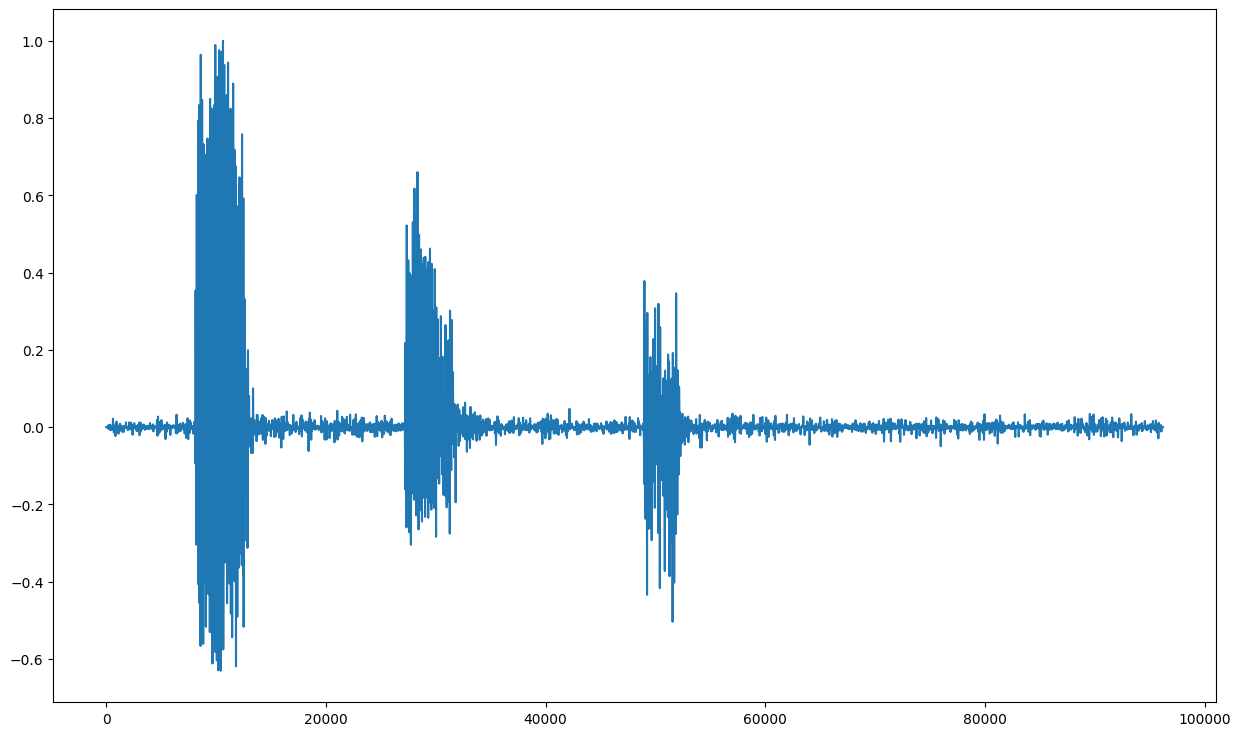

In [6]:
plt.plot(der)

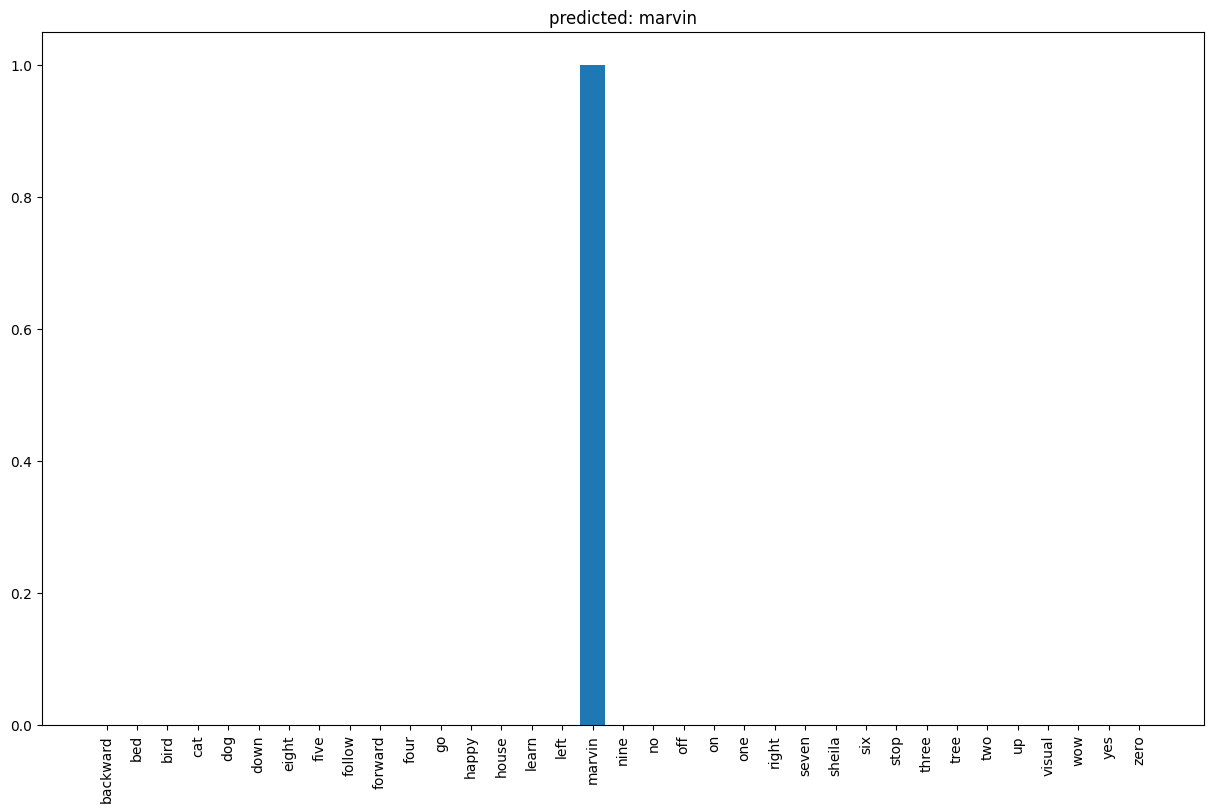

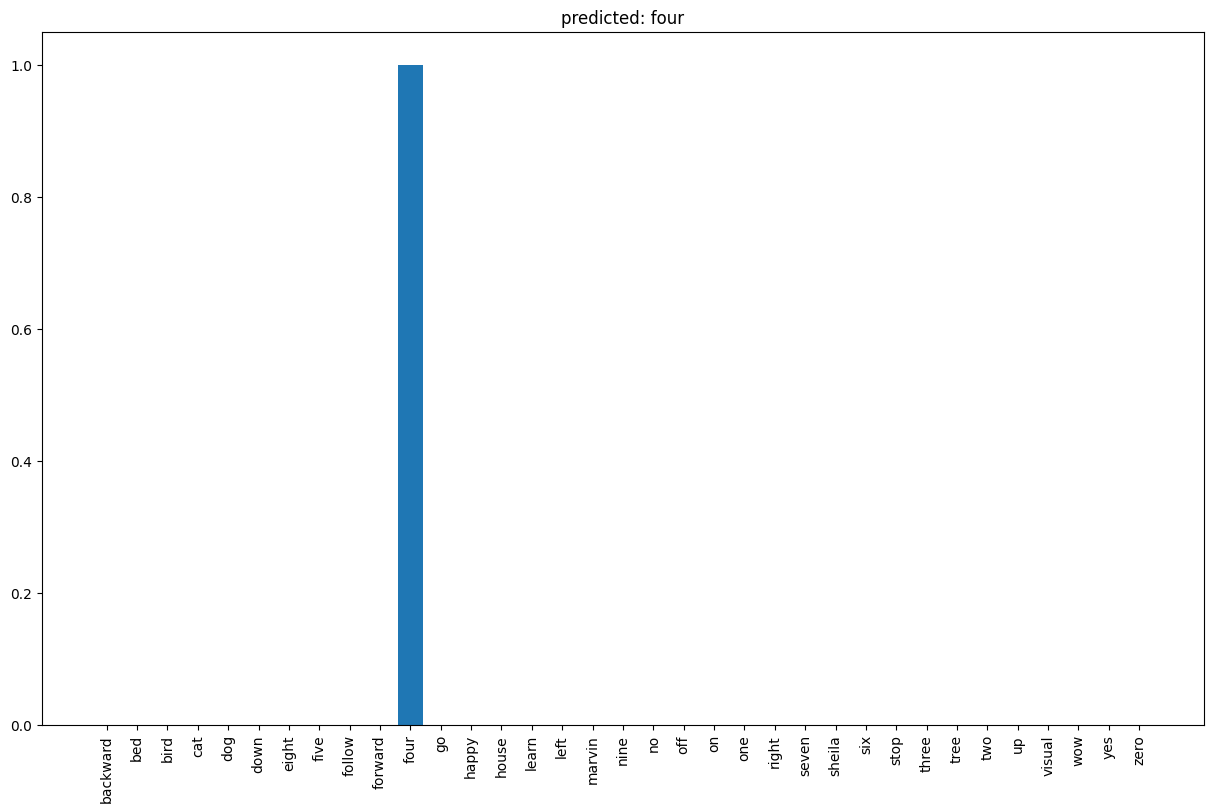

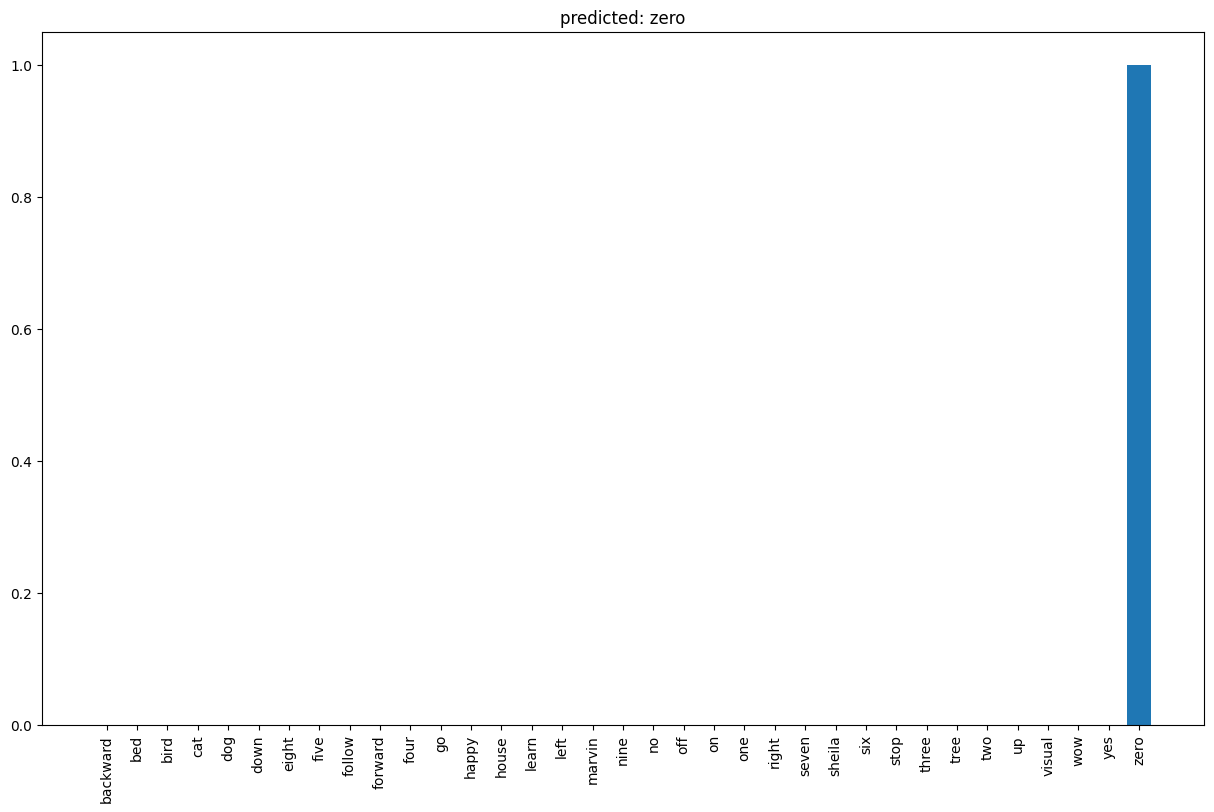

In [18]:
for i in range(len(problist)):

    plt.bar(x = wordlist, height=problist[i])
    plt.xticks(rotation=90)
    plt.title("predicted: " + predlist[i])
    plt.show()

In [47]:
MelMelinv = []
for chunk in chunks:
    Mel = librosa.feature.melspectrogram(y=chunk, sr=sr, n_mels=n_mels,hop_length=hop_length, win_length=win_length)
    Melinv = librosa.feature.inverse.mel_to_audio(Mel, sr=sr, hop_length=hop_length, win_length=win_length)
    MelMelinv.append(Melinv)
# Audio(chunk, rate=sr)
Audio(MelMelinv[2], rate=sr)